<a href="https://colab.research.google.com/github/Theresa-Gao-0529/MSSP607/blob/main/Week_13_Financial_Data_(1)(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 13 Financial Data

In [ ]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from IPython.display import display
from google.colab import files

print("Libraries imported successfully.")

Libraries imported successfully.


## Task 1

Tickers:
- Apple: AAPL
- Facebook: META
- Google: GOOGL
- Netflix: NFLX


In [ ]:
# Task 1: Read stock data directly from the GitHub repository
owner = 'Theresa-Gao-0529'
repository = 'MSSP607'
repo_url = f'https://github.com/{owner}/{repository}'
repo_path = Path('.') / repository
csv_path = 'data/week13/combined_stock_data.csv'
csv_url = f'https://raw.githubusercontent.com/{owner}/{repository}/main/{csv_path}'

combined_stock_data = pd.read_csv(csv_url)
combined_stock_data['Date'] = pd.to_datetime(combined_stock_data['Date'])
print(f'Data loaded from {repo_url}/{csv_path}')

apple = combined_stock_data[combined_stock_data['Ticker'] == 'AAPL'].set_index('Date')
facebook = combined_stock_data[combined_stock_data['Ticker'] == 'META'].set_index('Date')
google = combined_stock_data[combined_stock_data['Ticker'] == 'GOOGL'].set_index('Date')
netflix = combined_stock_data[combined_stock_data['Ticker'] == 'NFLX'].set_index('Date')

print("Apple Data:")
display(apple.head())

print("Facebook Data:")
display(facebook.head())

print("Google Data:")
display(google.head())

print("Netflix Data:")
display(netflix.head())

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Apple Data:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
1980-12-12,0.098048,0.128348,0.128906,0.128348,0.128348,469033600
1980-12-15,0.092933,0.121652,0.122210,0.121652,0.122210,175884800
1980-12-16,0.086112,0.112723,0.113281,0.112723,0.113281,105728000
1980-12-17,0.088243,0.115513,0.116071,0.115513,0.115513,86441600
1980-12-18,0.090801,0.118862,0.119420,0.118862,0.118862,73449600


Facebook Data:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META,META
Date,,,,,,
2012-05-18,37.867313,38.230000,45.000000,38.000000,42.049999,573576400
2012-05-21,33.707161,34.029999,36.660000,33.000000,36.529999,168192700
2012-05-22,30.705906,31.000000,33.590000,30.940001,32.610001,101786600
2012-05-23,31.696423,32.000000,32.500000,31.360001,31.370001,73600000
2012-05-24,32.716644,33.029999,33.209999,31.770000,32.950001,50237200


Google Data:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL
Date,,,,,,
2004-08-19,2.487342,2.511011,2.604104,2.401401,2.502503,893181924
2004-08-20,2.684911,2.710460,2.729730,2.515015,2.527778,456686856
2004-08-23,2.711932,2.737738,2.839840,2.728979,2.771522,365122512
2004-08-24,2.599637,2.624374,2.792793,2.591842,2.783784,304946748
2004-08-25,2.627649,2.652653,2.702703,2.599600,2.626627,183772044


Netflix Data:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,NFLX,NFLX,NFLX,NFLX,NFLX,NFLX
Date,,,,,,
2002-05-23,0.119643,0.119643,0.124286,0.114571,0.115643,1047900000
2002-05-24,0.121000,0.121000,0.122500,0.119714,0.121429,111048000
2002-05-28,0.115714,0.115714,0.123214,0.115714,0.121357,66094000
2002-05-29,0.110357,0.110357,0.116429,0.108571,0.116429,67578000
2002-05-30,0.107143,0.107143,0.110786,0.107143,0.110786,101542000


In [ ]:
# Check the size of each data frame

print("Apple:", apple.shape)
print("Facebook:", facebook.shape)
print("Google:", google.shape)
print("Netflix:", netflix.shape)

Apple: (11580, 6)
Facebook: (3650, 6)
Google: (5602, 6)
Netflix: (6166, 6)


## Task 2


In [ ]:
# Clean each data frame and add a ticker symbol
def clean_stock_data(df, ticker):
    df = df.copy()

    # Flatten MultiIndex columns if Yahoo Finance returns them
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df["Ticker"] = ticker
    return df

apple_clean = clean_stock_data(apple, "AAPL")
facebook_clean = clean_stock_data(facebook, "META")
google_clean = clean_stock_data(google, "GOOGL")
netflix_clean = clean_stock_data(netflix, "NFLX")

# Combine all four stock data frames
combined_stock_data = pd.concat(
    [apple_clean, facebook_clean, google_clean, netflix_clean],
    axis=0
).reset_index()

# Make sure Date has a consistent name
if "index" in combined_stock_data.columns and "Date" not in combined_stock_data.columns:
    combined_stock_data.rename(columns={"index": "Date"}, inplace=True)

display(combined_stock_data.head(10))

print("Combined DataFrame shape:", combined_stock_data.shape)
print("\nTicker counts:")
print(combined_stock_data["Ticker"].value_counts())

Price,Date,Adj Close,Close,High,Low,Open,Volume,Ticker
0,1980-12-12,0.098048,0.128348,0.128906,0.128348,0.128348,469033600,AAPL
1,1980-12-15,0.092933,0.121652,0.122210,0.121652,0.122210,175884800,AAPL
2,1980-12-16,0.086112,0.112723,0.113281,0.112723,0.113281,105728000,AAPL
3,1980-12-17,0.088243,0.115513,0.116071,0.115513,0.115513,86441600,AAPL
4,1980-12-18,0.090801,0.118862,0.119420,0.118862,0.118862,73449600,AAPL
5,1980-12-19,0.096343,0.126116,0.126674,0.126116,0.126116,48630400,AAPL
6,1980-12-22,0.101032,0.132254,0.132813,0.132254,0.132254,37363200,AAPL
7,1980-12-23,0.105295,0.137835,0.138393,0.137835,0.137835,46950400,AAPL
8,1980-12-24,0.110837,0.145089,0.145647,0.145089,0.145089,48003200,AAPL
9,1980-12-26,0.121068,0.158482,0.159040,0.158482,0.158482,55574400,AAPL


Combined DataFrame shape: (26998, 8)

Ticker counts:
Ticker
AAPL     11580
NFLX      6166
GOOGL     5602
META      3650
Name: count, dtype: int64


## Task 3

Required metrics:
- quickRatio
- currentRatio
- totalRevenue
- debtToEquity
- revenuePerShare
- returnOnAssets
- returnOnEquity
- grossProfits

In [ ]:
# Task 3: Retrieve the required financial metrics

tickers = {
    "Apple": "AAPL",
    "Facebook": "META",
    "Google": "GOOGL",
    "Netflix": "NFLX"
}

financial_metrics = [
    "quickRatio",
    "currentRatio",
    "totalRevenue",
    "debtToEquity",
    "revenuePerShare",
    "returnOnAssets",
    "returnOnEquity",
    "grossProfits"
]

def get_financial_metrics(ticker_symbol):
    ticker = yf.Ticker(ticker_symbol)

    try:
        info = ticker.info
    except Exception as e:
        print(f"Could not retrieve information for {ticker_symbol}: {e}")
        info = {}

    result = {}
    for metric in financial_metrics:
        value = info.get(metric, np.nan)
        result[metric] = np.nan if value is None else value

    return result

financial_data = []

for company, ticker_symbol in tickers.items():
    metrics = get_financial_metrics(ticker_symbol)
    metrics["Company"] = company
    metrics["Ticker"] = ticker_symbol
    financial_data.append(metrics)

financial_metrics_df = pd.DataFrame(financial_data)

financial_metrics_df = financial_metrics_df[
    ["Company", "Ticker"] + financial_metrics
]

display(financial_metrics_df)

,Company,Ticker,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
0,Apple,AAPL,0.827,1.023,478833999872,84.286,32.658,0.25868,1.42257,233602007040
1,Facebook,META,1.669,1.903,241605001216,42.161,95.186,0.14577,0.32264,195782000640
2,Google,GOOGL,2.512,2.786,471097999360,22.187,38.789,0.12743,0.44286,286698012672
3,Netflix,NFLX,0.836,1.075,49734631424,59.857,11.860,0.17124,0.53463,25207793664


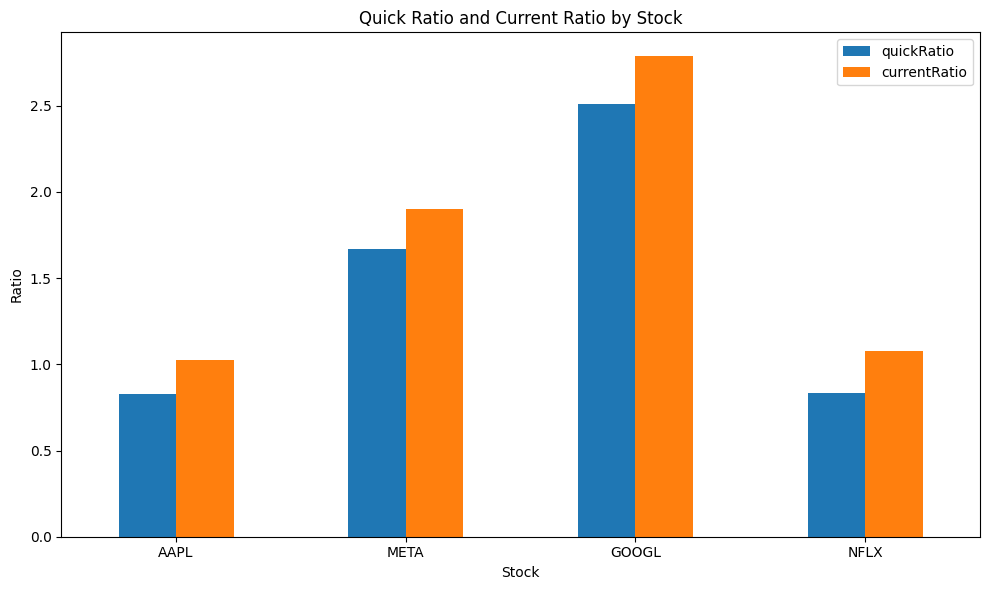

In [ ]:
# Task 3 Visualization 1: Quick Ratio and Current Ratio

liquidity_df = financial_metrics_df[
    ["Ticker", "quickRatio", "currentRatio"]
].set_index("Ticker")

ax = liquidity_df.plot(kind="bar", figsize=(10, 6))
ax.set_title("Quick Ratio and Current Ratio by Stock")
ax.set_xlabel("Stock")
ax.set_ylabel("Ratio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

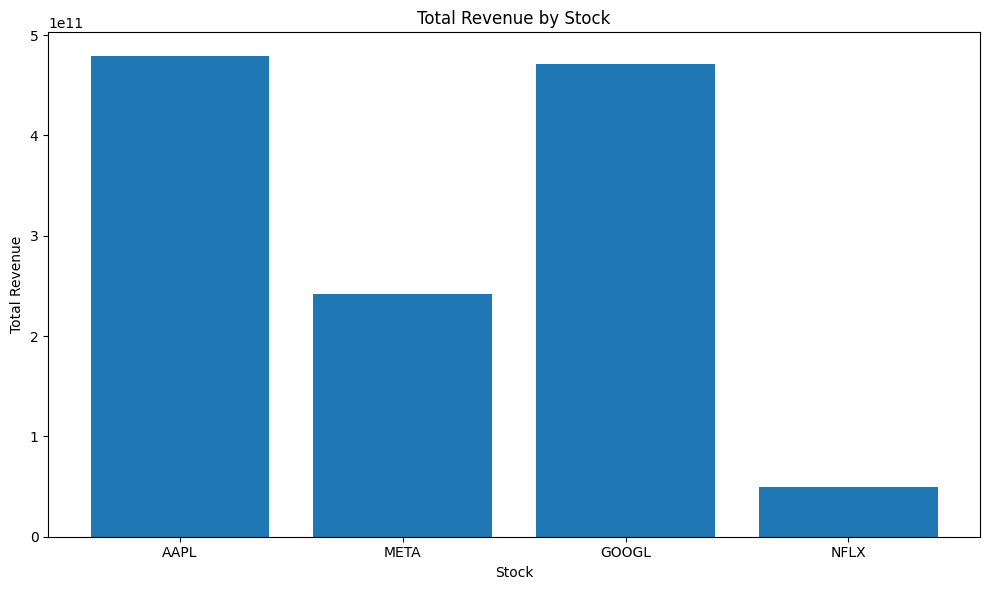

In [ ]:
# Task 3 Visualization 2: Total Revenue

plt.figure(figsize=(10, 6))
plt.bar(
    financial_metrics_df["Ticker"],
    financial_metrics_df["totalRevenue"]
)
plt.title("Total Revenue by Stock")
plt.xlabel("Stock")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

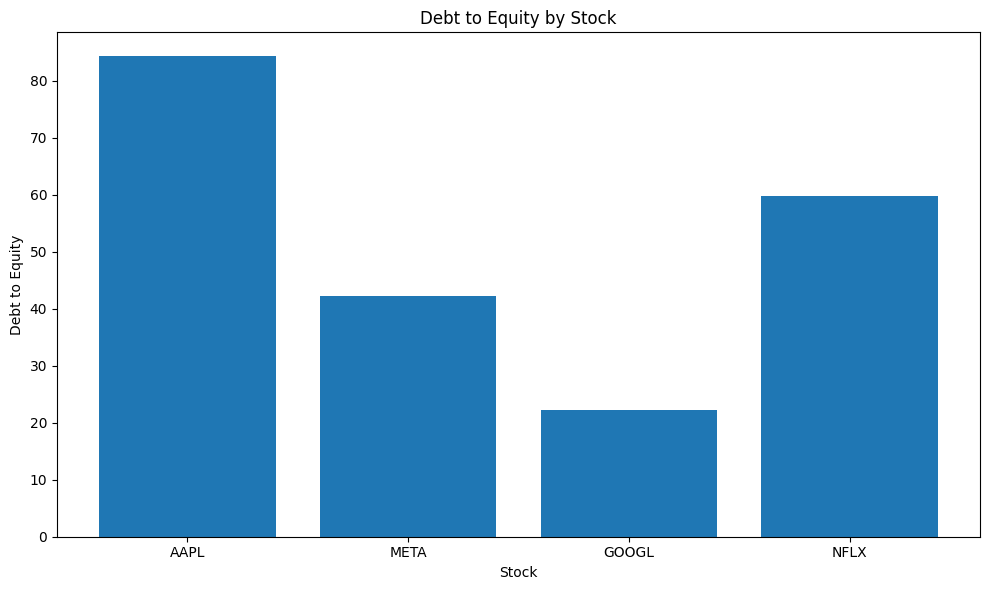

In [ ]:
# Task 3 Visualization 3: Debt to Equity

plt.figure(figsize=(10, 6))
plt.bar(
    financial_metrics_df["Ticker"],
    financial_metrics_df["debtToEquity"]
)
plt.title("Debt to Equity by Stock")
plt.xlabel("Stock")
plt.ylabel("Debt to Equity")
plt.tight_layout()
plt.show()

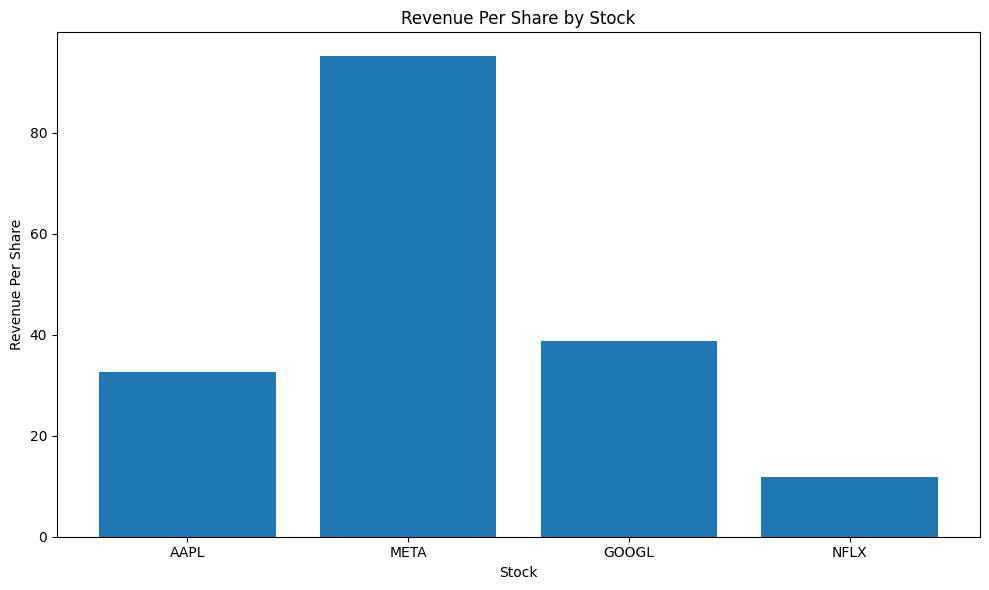

In [ ]:
# Task 3 Visualization 4: Revenue Per Share

plt.figure(figsize=(10, 6))
plt.bar(
    financial_metrics_df["Ticker"],
    financial_metrics_df["revenuePerShare"]
)
plt.title("Revenue Per Share by Stock")
plt.xlabel("Stock")
plt.ylabel("Revenue Per Share")
plt.tight_layout()
plt.show()

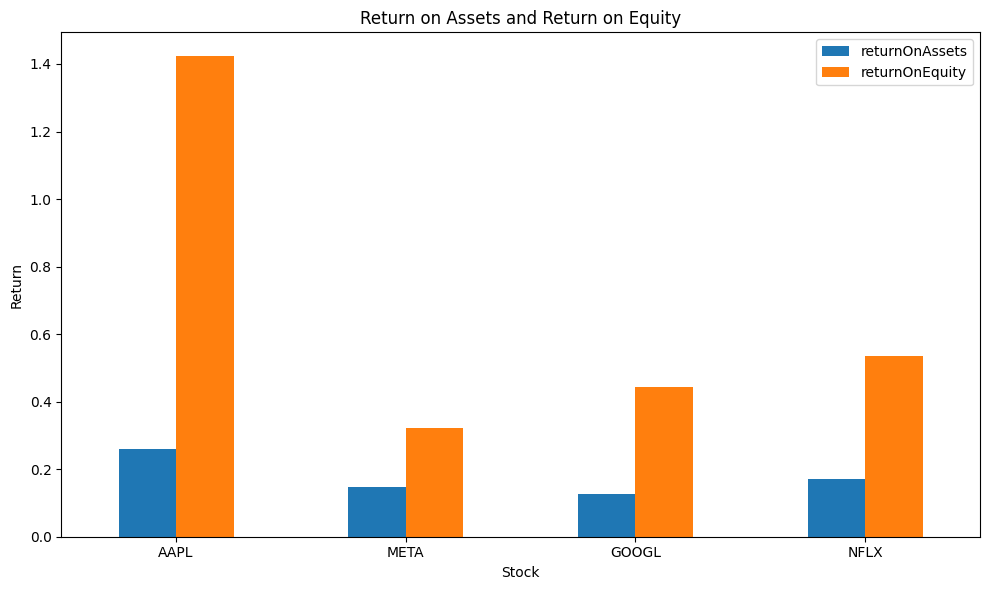

In [ ]:
# Task 3 Visualization 5: Return on Assets and Return on Equity

returns_df = financial_metrics_df[
    ["Ticker", "returnOnAssets", "returnOnEquity"]
].set_index("Ticker")

ax = returns_df.plot(kind="bar", figsize=(10, 6))
ax.set_title("Return on Assets and Return on Equity")
ax.set_xlabel("Stock")
ax.set_ylabel("Return")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

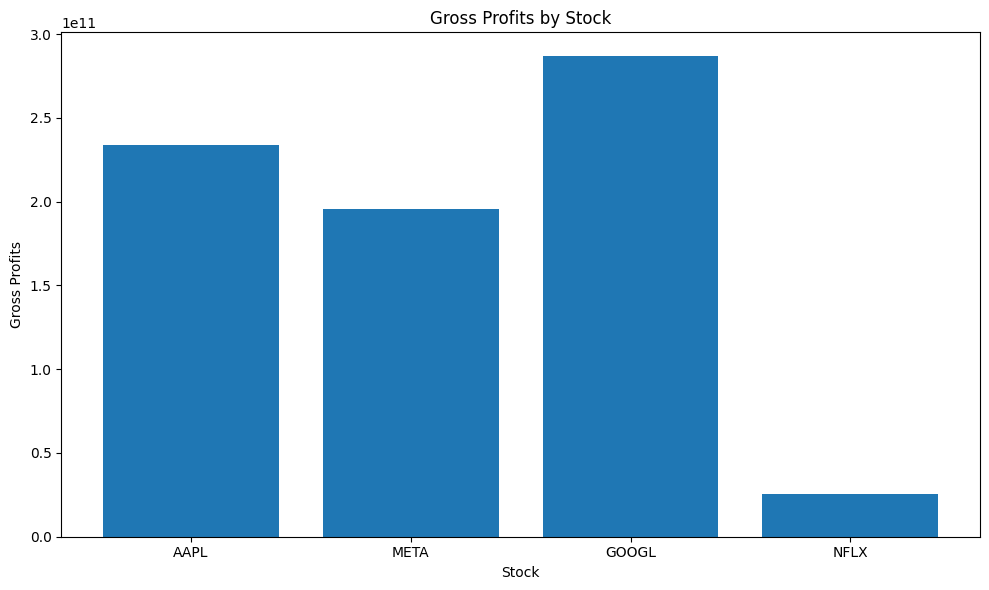

In [ ]:
# Task 3 Visualization 6: Gross Profits

plt.figure(figsize=(10, 6))
plt.bar(
    financial_metrics_df["Ticker"],
    financial_metrics_df["grossProfits"]
)
plt.title("Gross Profits by Stock")
plt.xlabel("Stock")
plt.ylabel("Gross Profits")
plt.tight_layout()
plt.show()

## Task 4



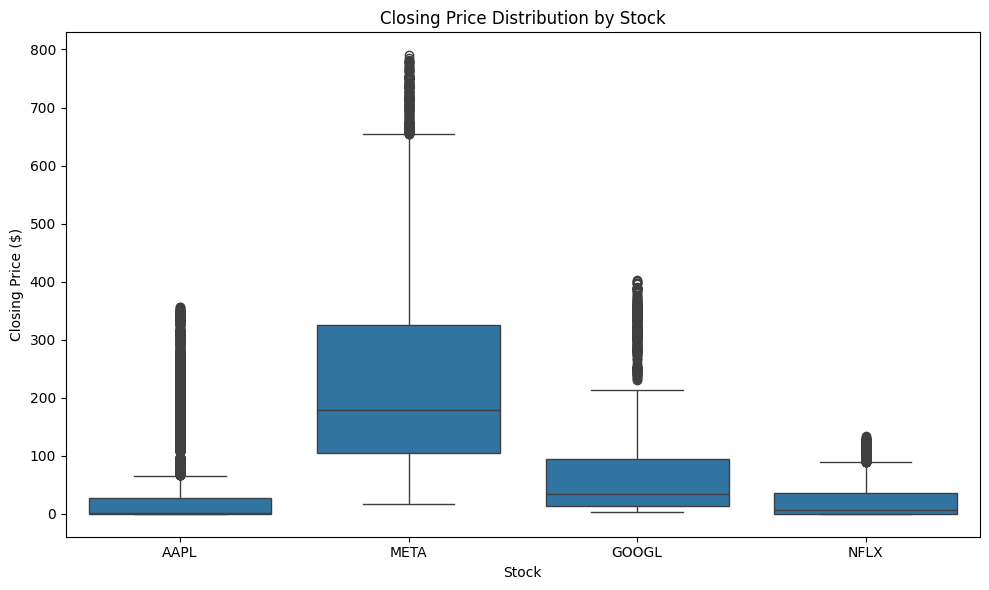

In [ ]:
# Task 4: Single boxplot for Closing Price

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=combined_stock_data,
    x="Ticker",
    y="Close"
)

plt.title("Closing Price Distribution by Stock")
plt.xlabel("Stock")
plt.ylabel("Closing Price ($)")
plt.tight_layout()
plt.show()

## Task 5

In [ ]:
# Task 5: Filter the combined data for calendar year 2023

combined_stock_data["Date"] = pd.to_datetime(
    combined_stock_data["Date"]
)

stock_2023 = combined_stock_data[
    (combined_stock_data["Date"] >= "2023-01-01") &
    (combined_stock_data["Date"] <= "2023-12-31")
].copy()

display(stock_2023.head())

print("2023 data shape:", stock_2023.shape)

Price,Date,Adj Close,Close,High,Low,Open,Volume,Ticker
10603,2023-01-03,122.783440,125.070000,130.899994,124.169998,130.279999,112117500,AAPL
10604,2023-01-04,124.049873,126.360001,128.660004,125.080002,126.889999,89113600,AAPL
10605,2023-01-05,122.734360,125.019997,127.769997,124.760002,127.129997,80962700,AAPL
10606,2023-01-06,127.250282,129.619995,130.289993,124.889999,126.010002,87754700,AAPL
10607,2023-01-09,127.770592,130.149994,133.410004,129.889999,130.470001,70790800,AAPL


2023 data shape: (1000, 8)


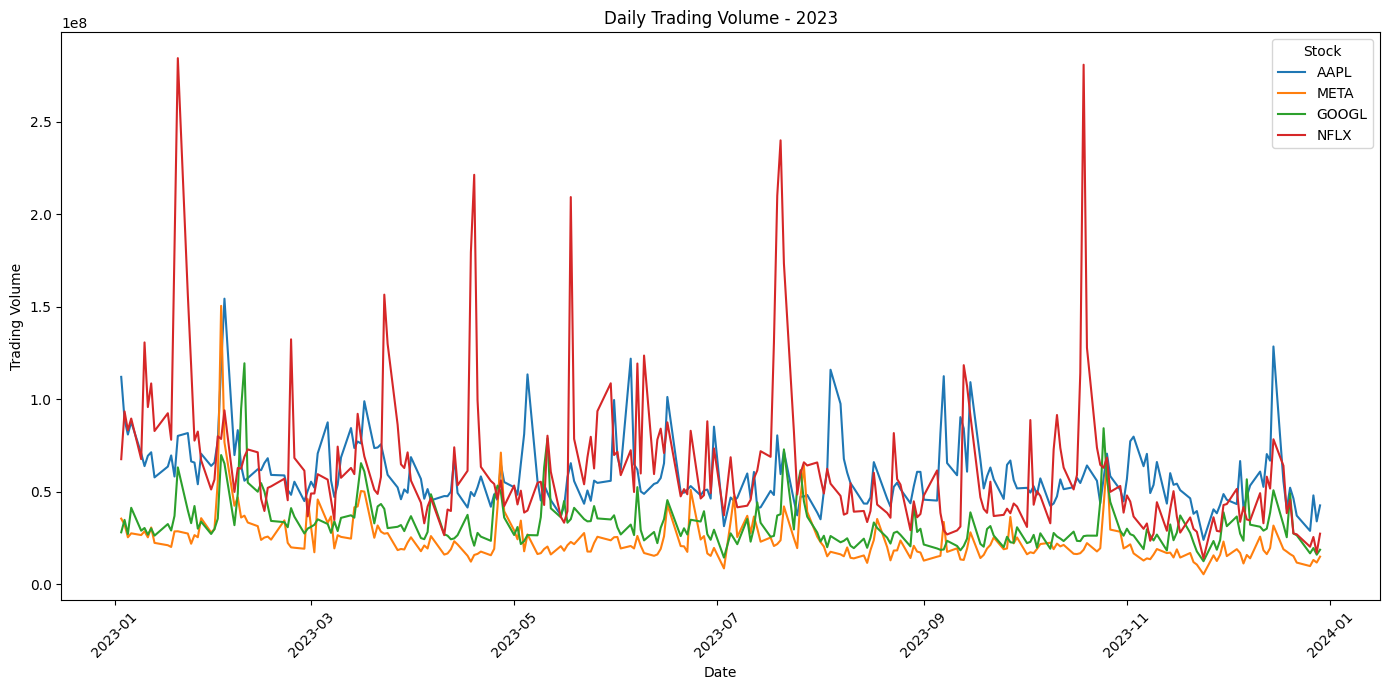

In [ ]:
# Task 5: Daily trading volume visualization for all four stocks

plt.figure(figsize=(14, 7))

for ticker in ["AAPL", "META", "GOOGL", "NFLX"]:
    stock_data = stock_2023[stock_2023["Ticker"] == ticker]

    plt.plot(
        stock_data["Date"],
        stock_data["Volume"],
        label=ticker
    )

plt.title("Daily Trading Volume - 2023")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.legend(title="Stock")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

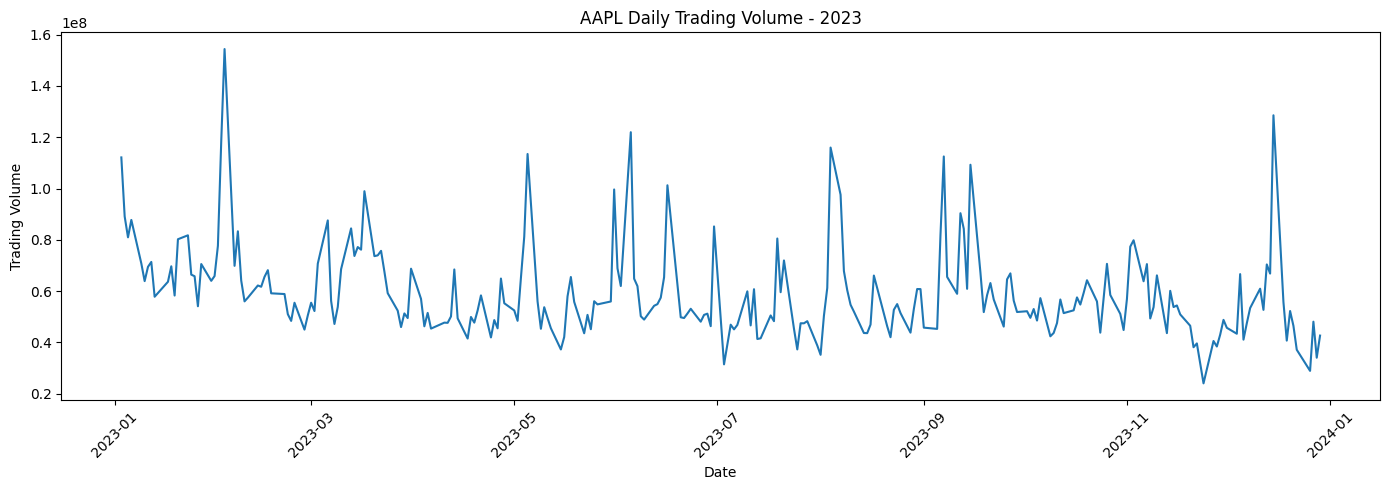

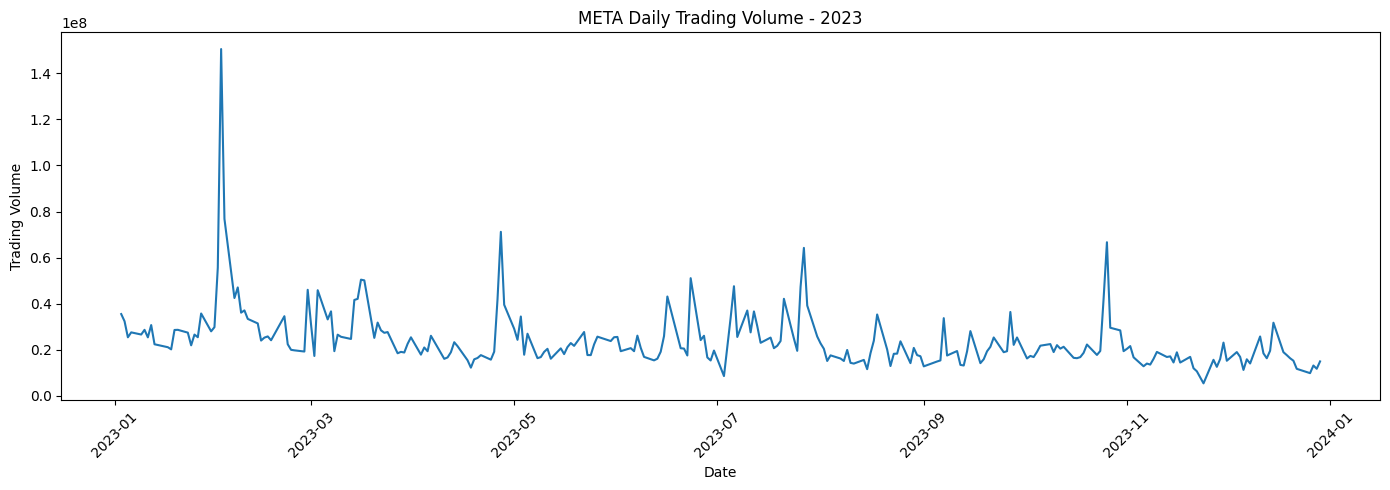

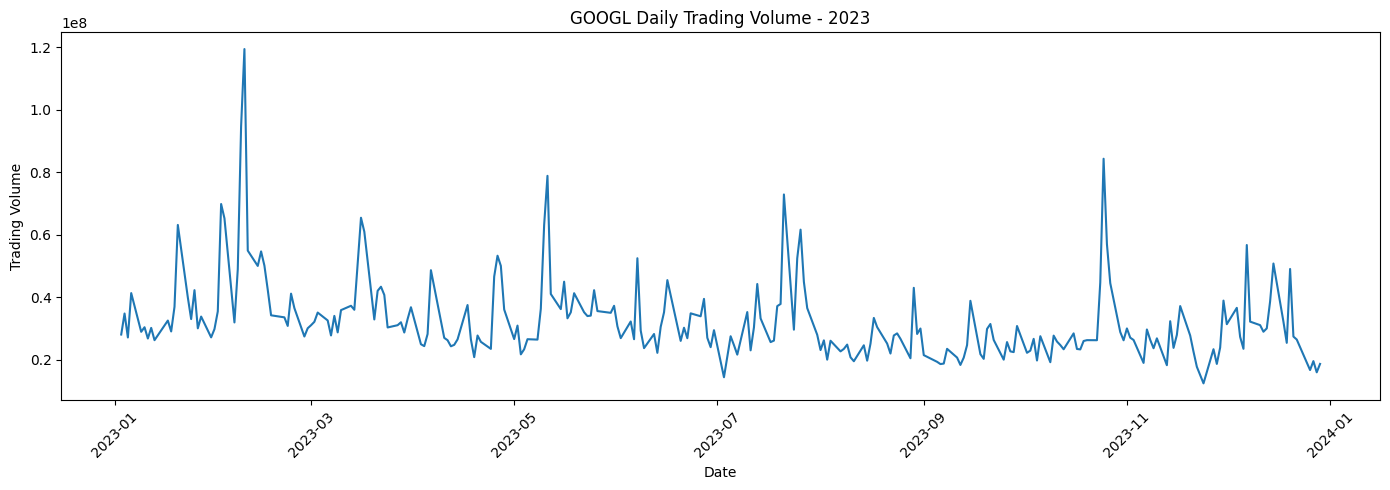

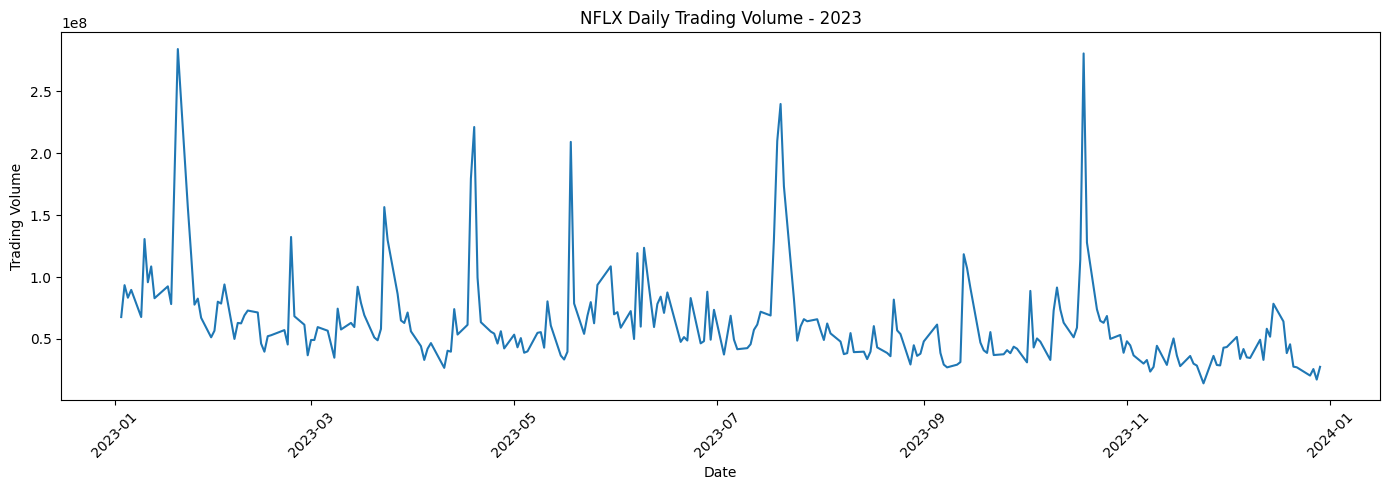

In [ ]:
# Optional clearer view: one trading-volume chart per stock

for ticker in ["AAPL", "META", "GOOGL", "NFLX"]:
    stock_data = stock_2023[stock_2023["Ticker"] == ticker]

    plt.figure(figsize=(14, 5))
    plt.plot(stock_data["Date"], stock_data["Volume"])

    plt.title(f"{ticker} Daily Trading Volume - 2023")
    plt.xlabel("Date")
    plt.ylabel("Trading Volume")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Task 6

In [ ]:
# Task 6: Save the combined stock data to CSV

csv_filename = "combined_stock_data.csv"

combined_stock_data.to_csv(
    csv_filename,
    index=False
)

print(f"CSV file saved successfully as: {csv_filename}")

CSV file saved successfully as: combined_stock_data.csv


In [ ]:
# Verify the CSV file

check_df = pd.read_csv("combined_stock_data.csv")

print("CSV shape:", check_df.shape)
print("\nColumns:")
print(check_df.columns.tolist())

print("\nTicker counts:")
print(check_df["Ticker"].value_counts())

display(check_df.head())

CSV shape: (26998, 8)

Columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Ticker']

Ticker counts:
Ticker
AAPL     11580
NFLX      6166
GOOGL     5602
META      3650
Name: count, dtype: int64


,Date,Adj Close,Close,High,Low,Open,Volume,Ticker
0,1980-12-12,0.098048,0.128348,0.128906,0.128348,0.128348,469033600,AAPL
1,1980-12-15,0.092933,0.121652,0.122210,0.121652,0.122210,175884800,AAPL
2,1980-12-16,0.086112,0.112723,0.113281,0.112723,0.113281,105728000,AAPL
3,1980-12-17,0.088243,0.115513,0.116071,0.115513,0.115513,86441600,AAPL
4,1980-12-18,0.090801,0.118862,0.119420,0.118862,0.118862,73449600,AAPL


In [ ]:
# Download the CSV

files.download("combined_stock_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>